In [2]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine Learning algorithms
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import ExtraTreesRegressor

# Model evaluation
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Save model
import joblib

import warnings
warnings.filterwarnings('ignore')


In [3]:
df = pd.read_csv("/content/car data.csv")
#Display First 5 rows
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [4]:

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDescribe Dataset:")
print(df.describe())

Dataset Shape: (301, 9)

Column Names:
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Selling_type   301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB

Missing Values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission   

In [5]:
print("\nduplicate Values")
print(df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()


duplicate Values
2


In [6]:
df.columns = df.columns.str.strip()

In [7]:
print(df.shape)

print(df.isnull().sum())

(299, 9)
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64


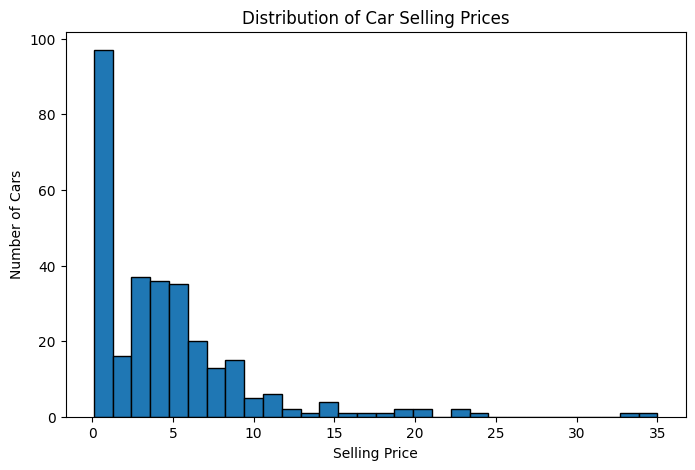

In [19]:
#Selling Price Distribution
plt.figure(figsize=(8,5))

plt.hist(df['Selling_Price'], bins=30, edgecolor='black')

plt.title("Distribution of Car Selling Prices")

plt.xlabel("Selling Price")

plt.ylabel("Number of Cars")

plt.show()

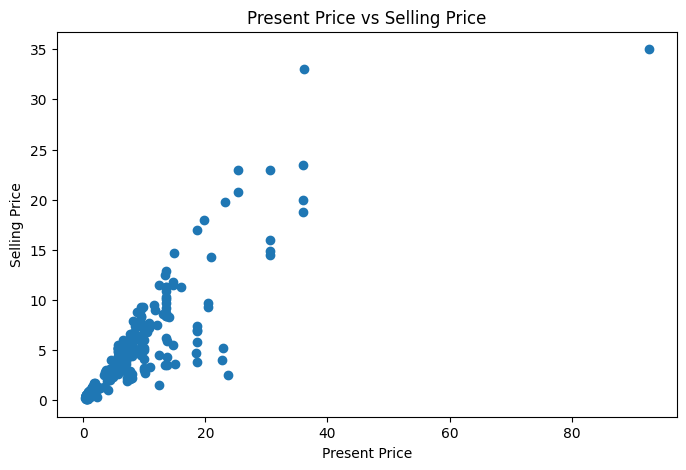

In [20]:
#Present Price vs Selling Price
plt.figure(figsize=(8,5))

plt.scatter(df['Present_Price'], df['Selling_Price'])

plt.title("Present Price vs Selling Price")

plt.xlabel("Present Price")

plt.ylabel("Selling Price")

plt.show()

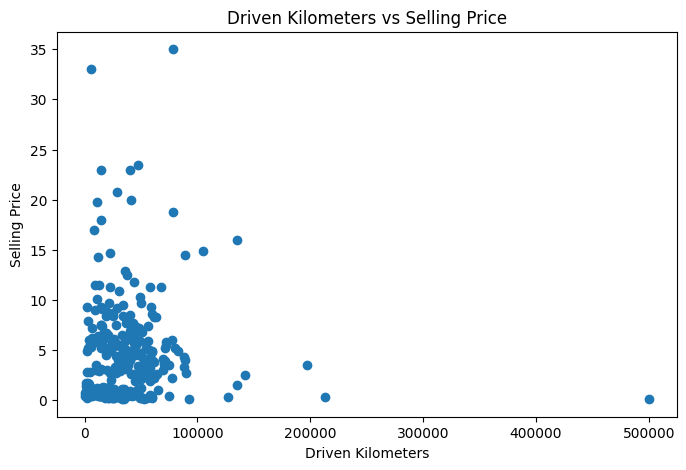

In [21]:
#Kilometres Driven vs Selling Price
plt.figure(figsize=(8,5))

plt.scatter(df['Driven_kms'], df['Selling_Price'])

plt.title("Driven Kilometers vs Selling Price")

plt.xlabel("Driven Kilometers")

plt.ylabel("Selling Price")

plt.show()

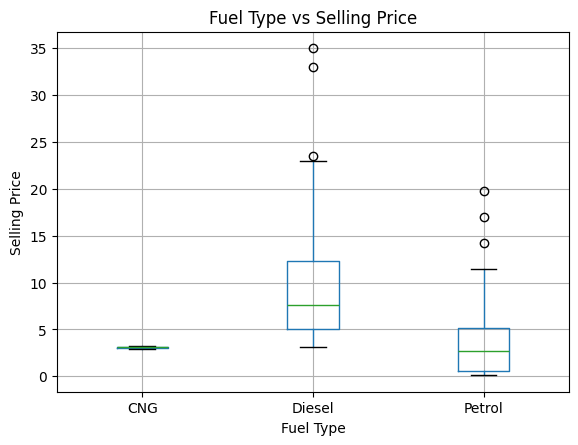

In [22]:
#Fuel Type Analysis
df.boxplot(column='Selling_Price', by='Fuel_Type')

plt.title("Fuel Type vs Selling Price")

plt.suptitle("")

plt.xlabel("Fuel Type")

plt.ylabel("Selling Price")

plt.show()

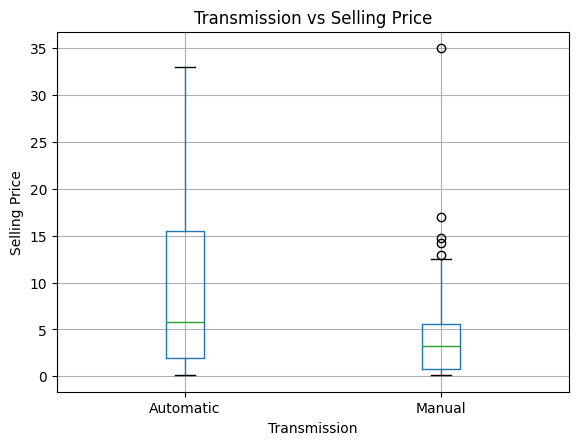

In [23]:
#Transmission Analysis
df.boxplot(column='Selling_Price', by='Transmission')

plt.title("Transmission vs Selling Price")

plt.suptitle("")

plt.xlabel("Transmission")

plt.ylabel("Selling Price")

plt.show()

In [24]:
#Feature Engineering
# Get current year

current_year = pd.Timestamp.now().year

# Create Car Age feature

df['Car_Age'] = current_year - df['Year']

# Display updated dataset

df.head()

,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner,Car_Age
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0,12
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0,13
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0,9
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0,15
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0,12


In [25]:
if 'Car_Name' in df.columns:

    df['Brand'] = df['Car_Name'].str.split().str[0]

df.head()

,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner,Car_Age,Brand
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0,12,ritz
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0,13,sx4
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0,9,ciaz
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0,15,wagon
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0,12,swift


In [26]:
# Independent variables

X = df.drop(['Selling_Price'], axis=1)

# Dependent variable

y = df['Selling_Price']

print("Independent Variables:")
print(X.columns)

print("\nDependent Variable:")
print(y.name)

Independent Variables:
Index(['Car_Name', 'Year', 'Present_Price', 'Driven_kms', 'Fuel_Type',
       'Selling_type', 'Transmission', 'Owner', 'Car_Age', 'Brand'],
      dtype='object')

Dependent Variable:
Selling_Price


In [27]:
X = X.drop(
    columns=['Car_Name'],
    errors='ignore'
)

In [28]:
# Identify numerical columns

numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Identify categorical columns

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['Year', 'Present_Price', 'Driven_kms', 'Owner', 'Car_Age']

Categorical Features:
['Fuel_Type', 'Selling_type', 'Transmission', 'Brand']


In [29]:
#Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (239, 9)
Testing Data: (60, 9)


In [30]:
#Data Preprocessing
#Numerical Preprocessing
numeric_transformer = Pipeline(steps=[

    ('imputer', SimpleImputer(strategy='median')),

    ('scaler', StandardScaler())

])

In [31]:
#Categorical Preprocessing
categorical_transformer = Pipeline(steps=[

    ('imputer', SimpleImputer(strategy='most_frequent')),

    ('encoder', OneHotEncoder(handle_unknown='ignore'))

])

In [32]:
#Combine Preprocessing
preprocessor = ColumnTransformer(

    transformers=[

        ('num', numeric_transformer, numeric_features),

        ('cat', categorical_transformer, categorical_features)

    ]

)

In [33]:
#Train Linear Regression Model
# Create pipeline

lr_model = Pipeline(steps=[

    ('preprocessor', preprocessor),

    ('model', LinearRegression())

])

# Train model

lr_model.fit(X_train, y_train)

# Predictions

lr_predictions = lr_model.predict(X_test)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [34]:
#Train Rendom Forest Regression
rf_model = Pipeline(steps=[

    ('preprocessor', preprocessor),

    ('model', RandomForestRegressor(

        n_estimators=300,

        random_state=42

    ))

])

# Train model

rf_model.fit(X_train, y_train)

# Predictions

rf_predictions = rf_model.predict(X_test)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [35]:
#Train Extra Trees Regression
et_model = Pipeline(steps=[

    ('preprocessor', preprocessor),

    ('model', ExtraTreesRegressor(

        n_estimators=300,

        random_state=42

    ))

])

# Train model

et_model.fit(X_train, y_train)

# Predictions

et_predictions = et_model.predict(X_test)

print("Extra Trees Model Trained Successfully!")

Extra Trees Model Trained Successfully!


In [36]:
#Model Evaluation
def evaluate_model(y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)

    mse = mean_squared_error(y_true, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_true, y_pred)

    return mae, rmse, r2

In [37]:
#Evaluate Linear Regression
lr_mae, lr_rmse, lr_r2 = evaluate_model(
    y_test,
    lr_predictions
)

In [38]:
#Evaluating Random Forest
rf_mae, rf_rmse, rf_r2 = evaluate_model(
    y_test,
    rf_predictions
)

In [39]:
#Evaluate Extra Trees
et_mae, et_rmse, et_r2 = evaluate_model(
    y_test,
    et_predictions
)

In [40]:
#Comparing All Models
results = pd.DataFrame({

    'Model': [
        'Linear Regression',
        'Random Forest',
        'Extra Trees'
    ],

    'MAE': [
        lr_mae,
        rf_mae,
        et_mae
    ],

    'RMSE': [
        lr_rmse,
        rf_rmse,
        et_rmse
    ],

    'R2 Score': [
        lr_r2,
        rf_r2,
        et_r2
    ]

})

results = results.sort_values(
    by='RMSE'
)

display(results)

,Model,MAE,RMSE,R2 Score
2,Extra Trees,0.830271,1.753815,0.880657
0,Linear Regression,1.473766,2.793939,0.697124
1,Random Forest,1.418354,3.447066,0.538969


In [41]:
#Finding Best MOdels
best_model_name = results.iloc[0]['Model']

print("Best Model:", best_model_name)

Best Model: Extra Trees


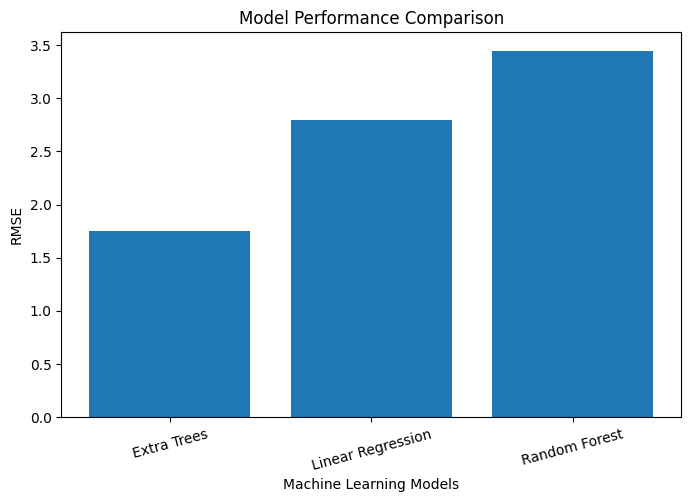

In [42]:
#Model Performance Visualization
plt.figure(figsize=(8,5))

plt.bar(results['Model'], results['RMSE'])

plt.title("Model Performance Comparison")

plt.xlabel("Machine Learning Models")

plt.ylabel("RMSE")

plt.xticks(rotation=15)

plt.show()

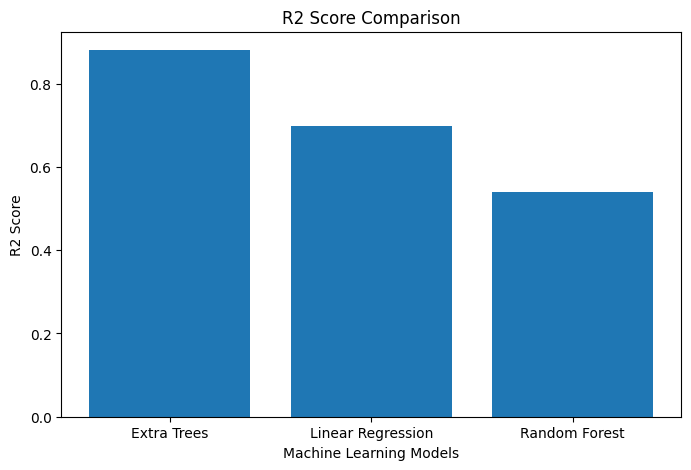

In [43]:
#Compare R^2 Scores
plt.figure(figsize=(8,5))

plt.bar(results['Model'], results['R2 Score'])

plt.title("R2 Score Comparison")

plt.xlabel("Machine Learning Models")

plt.ylabel("R2 Score")

plt.show()

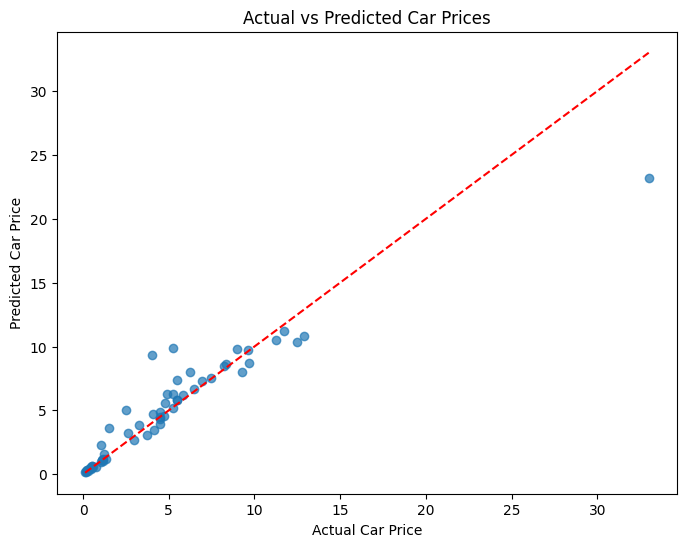

In [44]:
#Actual vs Predicted Price
# Use the best-performing model

models = {

    'Linear Regression': lr_model,

    'Random Forest': rf_model,

    'Extra Trees': et_model

}

best_model = models[best_model_name]

best_predictions = best_model.predict(X_test)

plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.7
)

minimum = min(y_test.min(), best_predictions.min())

maximum = max(y_test.max(), best_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    'r--'
)

plt.xlabel("Actual Car Price")

plt.ylabel("Predicted Car Price")

plt.title("Actual vs Predicted Car Prices")

plt.show()

In [45]:
#Checking Prediction Errors
prediction_df = pd.DataFrame({

    'Actual_Price': y_test.values,

    'Predicted_Price': best_predictions

})

prediction_df['Error'] = (
    prediction_df['Actual_Price'] -
    prediction_df['Predicted_Price']
)

prediction_df['Absolute_Error'] = prediction_df['Error'].abs()

display(prediction_df.head(10))

,Actual_Price,Predicted_Price,Error,Absolute_Error
0,8.99,9.798800,-0.808800,0.808800
1,8.35,8.594300,-0.244300,0.244300
2,0.45,0.466000,-0.016000,0.016000
3,7.45,7.497667,-0.047667,0.047667
4,5.25,9.896200,-4.646200,4.646200
5,5.25,5.218333,0.031667,0.031667
6,5.85,6.189667,-0.339667,0.339667
7,1.15,1.221167,-0.071167,0.071167
8,9.25,8.016000,1.234000,1.234000
9,0.38,0.486500,-0.106500,0.106500


In [47]:
#Saving The Trained Model
joblib.dump(
    best_model,
    'car_price_prediction_model.pkl'
)


['car_price_prediction_model.pkl']

In [48]:
#Loading Saved Models
loaded_model = joblib.load(
    'car_price_prediction_model.pkl'
)


In [49]:
#Predict The Price of New Car
# Create sample input using test dataset structure

new_car = X_test.iloc[[0]].copy()

# Display input

display(new_car)

# Predict price

predicted_price = loaded_model.predict(new_car)

print("Predicted Car Selling Price:")

print(predicted_price[0])

,Year,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner,Car_Age,Brand
283,2016,11.8,9010,Petrol,Dealer,Manual,0,10,city


Predicted Car Selling Price:
9.798800000000004


In [50]:
if 'Present_Price' in new_car.columns:
    new_car.loc[:, 'Present_Price'] = 8.5

if 'Driven_kms' in new_car.columns:
    new_car.loc[:, 'Driven_kms'] = 25000

if 'Fuel_Type' in new_car.columns:
    new_car.loc[:, 'Fuel_Type'] = 'Petrol'

if 'Transmission' in new_car.columns:
    new_car.loc[:, 'Transmission'] = 'Manual'

if 'Owner' in new_car.columns:
    new_car.loc[:, 'Owner'] = 0

if 'Car_Age' in new_car.columns:
    new_car.loc[:, 'Car_Age'] = 3

predicted_price = loaded_model.predict(new_car)

print("Estimated Car Price:", predicted_price[0])

Estimated Car Price: 7.511266666666671


In [51]:
import joblib

# Save trained model

joblib.dump(
    best_model,
    "car_price_prediction_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [52]:
import os

print(os.getcwd())
print(os.listdir())

/content
['.config', 'car data.csv', 'car_price_prediction_model.pkl', 'sample_data']


In [54]:
!python -c "import sklearn; print(sklearn.__version__)"

1.6.1


In [55]:
import joblib
import os
import sklearn

print("Scikit-learn Version:", sklearn.__version__)

model_path = os.path.join(
    os.getcwd(),
    "car_price_prediction_model.pkl"
)

joblib.dump(best_model, model_path)

print("Model saved successfully!")
print("Model location:", model_path)

Scikit-learn Version: 1.6.1
Model saved successfully!
Model location: /content/car_price_prediction_model.pkl


In [56]:
import sklearn
import sys

print("Python:", sys.executable)
print("Scikit-learn:", sklearn.__version__)

Python: /usr/bin/python3
Scikit-learn: 1.6.1


In [57]:
import joblib

joblib.dump(
    best_model,
    "car_price_prediction_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [58]:
import joblib

joblib.dump(best_model, "car_price_prediction_model.pkl")

print("Model saved successfully!")

Model saved successfully!
